
# BrainScanAI-V2 — Classification EDA

## Objective

Explore and validate the brain MRI classification dataset before training InceptionV3.

We will:
1. Inspect the dataset structure.
2. Count images in each class.
3. Check file extensions and image integrity.
4. Visualize sample images.
5. Analyze image dimensions and class imbalance.
6. Prepare reproducible training, validation, and test sets.



## 1. Import Libraries and Inspect Dataset Structure

We begin by importing the libraries needed for data exploration.

Then, we locate the classification dataset and inspect its directory structure to understand how the MRI images are organized.


In [2]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

# Locate the project root
current_dir = Path.cwd()

if (current_dir / "datasets" / "classification").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "datasets" / "classification").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Cannot find datasets/classification. "
        "Check your notebook location."
    )

DATASET_DIR = PROJECT_ROOT / "datasets" / "classification"

print("Project root:", PROJECT_ROOT)
print("Classification dataset:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())


Project root: /home/lahcen404/YouCode-Y2/BrainScanAI-V2
Classification dataset: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/classification
Dataset exists: True


## 2. Locate the Dataset

Before analyzing the data, we need to locate the project root and the classification dataset.

Using `Path` instead of manually writing absolute paths makes the notebook easier to reuse on another machine.

In [3]:
current_dir = Path.cwd()

if (current_dir / "datasets" / "classification").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "datasets" / "classification").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Cannot find datasets/classification. "
        "Check the notebook location."
    )

DATASET_DIR = PROJECT_ROOT / "datasets" / "classification"

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

Project root: /home/lahcen404/YouCode-Y2/BrainScanAI-V2
Dataset directory: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/classification
Dataset exists: True


##  Inspect Dataset Structure

We explore the dataset folders to identify the splits (`Train`, `Val`) and the four MRI classes.

- `rglob("*")` searches recursively through all subfolders.
- `is_dir()` selects directories only.
- `relative_to()` displays paths relative to the project root.

In [4]:
for path in sorted(DATASET_DIR.rglob("*")):
    if path.is_dir():
        print(path.relative_to(PROJECT_ROOT))

datasets/classification/Train
datasets/classification/Train/Glioma
datasets/classification/Train/Glioma/images
datasets/classification/Train/Glioma/labels
datasets/classification/Train/Meningioma
datasets/classification/Train/Meningioma/images
datasets/classification/Train/Meningioma/labels
datasets/classification/Train/No Tumor
datasets/classification/Train/No Tumor/images
datasets/classification/Train/No Tumor/labels
datasets/classification/Train/Pituitary
datasets/classification/Train/Pituitary/images
datasets/classification/Train/Pituitary/labels
datasets/classification/Val
datasets/classification/Val/Glioma
datasets/classification/Val/Glioma/images
datasets/classification/Val/Glioma/labels
datasets/classification/Val/Meningioma
datasets/classification/Val/Meningioma/images
datasets/classification/Val/Meningioma/labels
datasets/classification/Val/No Tumor
datasets/classification/Val/No Tumor/images
datasets/classification/Val/No Tumor/labels
datasets/classification/Val/Pituitary
da

## 4. Count Images by Class

The number of images in each class helps us understand the dataset distribution.

A **class imbalance** occurs when some classes contain significantly more images than others. This can affect model performance and make accuracy alone misleading.

We will count supported image files in each class folder.

In [5]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []

for split_dir in sorted(DATASET_DIR.iterdir()):
    if not split_dir.is_dir():
        continue

    for class_dir in sorted(split_dir.iterdir()):
        images_dir = class_dir / "images"

        if not images_dir.is_dir():
            continue

        image_files = [
            file for file in images_dir.iterdir()
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        ]

        records.append({
            "split": split_dir.name,
            "class": class_dir.name,
            "image_count": len(image_files)
        })

class_counts = pd.DataFrame(records)
class_counts

,split,class,image_count
0,Train,Glioma,1153
1,Train,Meningioma,1449
2,Train,No Tumor,711
3,Train,Pituitary,1424
4,Val,Glioma,136
5,Val,Meningioma,140
6,Val,No Tumor,100
7,Val,Pituitary,136


## 5. Visualize Class Distribution

Visualize the number of images per class in each split to compare class frequencies and identify potential imbalance.

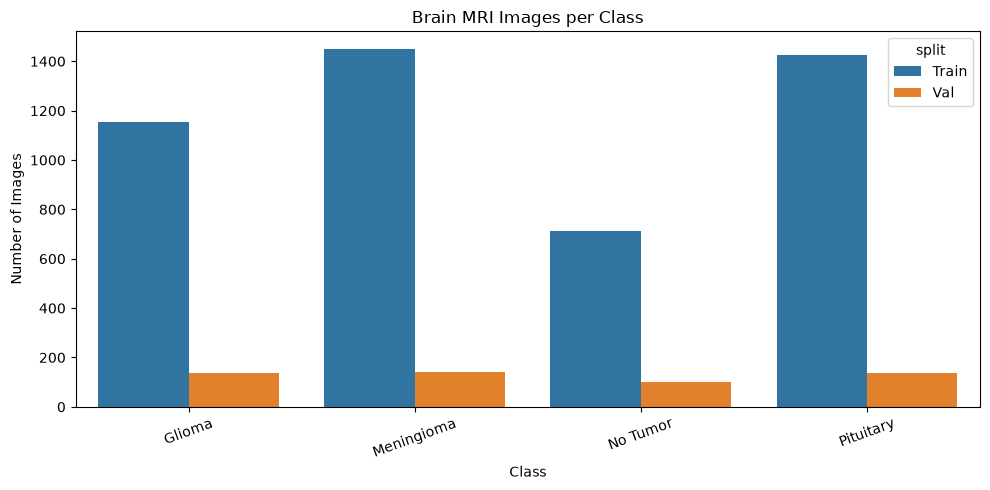

In [6]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_counts,
    x="class",
    y="image_count",
    hue="split"
)

plt.title("Brain MRI Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 6. Image Integrity and Dimensions

Check whether images are readable and inspect their dimensions, color modes, and file formats to identify potential data-quality issues.

In [7]:
image_records = []
corrupted_images = []

for split_dir in sorted(DATASET_DIR.iterdir()):
    if not split_dir.is_dir():
        continue

    for class_dir in sorted(split_dir.iterdir()):
        images_dir = class_dir / "images"

        if not images_dir.is_dir():
            continue

        for image_path in images_dir.iterdir():
            if not image_path.is_file():
                continue

            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            try:
                with Image.open(image_path) as img:
                    img.verify()

                with Image.open(image_path) as img:
                    image_records.append({
                        "split": split_dir.name,
                        "class": class_dir.name,
                        "filename": image_path.name,
                        "width": img.width,
                        "height": img.height,
                        "mode": img.mode,
                        "format": img.format,
                    })

            except Exception as error:
                corrupted_images.append({
                    "path": str(image_path),
                    "error": str(error),
                })

image_info = pd.DataFrame(image_records)

print("Readable images:", len(image_info))
print("Corrupted/unreadable images:", len(corrupted_images))

image_info.head()

Readable images: 5249
Corrupted/unreadable images: 0


,split,class,filename,width,height,mode,format
0,Train,Glioma,Te-glTr_0000.jpg,512,512,RGB,JPEG
1,Train,Glioma,Te-glTr_0005.jpg,512,512,RGB,JPEG
2,Train,Glioma,Te-glTr_0007.jpg,512,512,RGB,JPEG
3,Train,Glioma,Te-gl_0014.jpg,512,512,RGB,JPEG
4,Train,Glioma,Te-gl_0015.jpg,512,512,RGB,JPEG


### 6.1. Analyze Image Dimensions and Formats

Analyze image dimensions, color modes, and formats across the dataset to identify inconsistencies and potential preprocessing requirements.

In [8]:
print("Image dimensions:")
print(image_info.groupby(["width", "height"]).size().sort_values(ascending=False))

print("\nColor modes:")
print(image_info["mode"].value_counts())

print("\nImage formats:")
print(image_info["format"].value_counts())

print("\nImages per split:")
print(image_info.groupby("split").size())

print("\nCorrupted images:")
print(len(corrupted_images))


Image dimensions:
width  height
512    512       4206
225    225        119
630    630         66
442    442         42
236    236         33
                 ... 
590    332          1
600    519          1
       600          1
626    575          1
1375   1446         1
Length: 325, dtype: int64

Color modes:
mode
RGB     4247
L        998
RGBA       3
P          1
Name: count, dtype: int64

Image formats:
format
JPEG    5245
PNG        4
Name: count, dtype: int64

Images per split:
split
Train    4737
Val       512
dtype: int64

Corrupted images:
0


## 7. Visualize Sample MRI Images

Display sample images from each class to visually inspect the dataset and identify obvious inconsistencies or potential labeling issues.

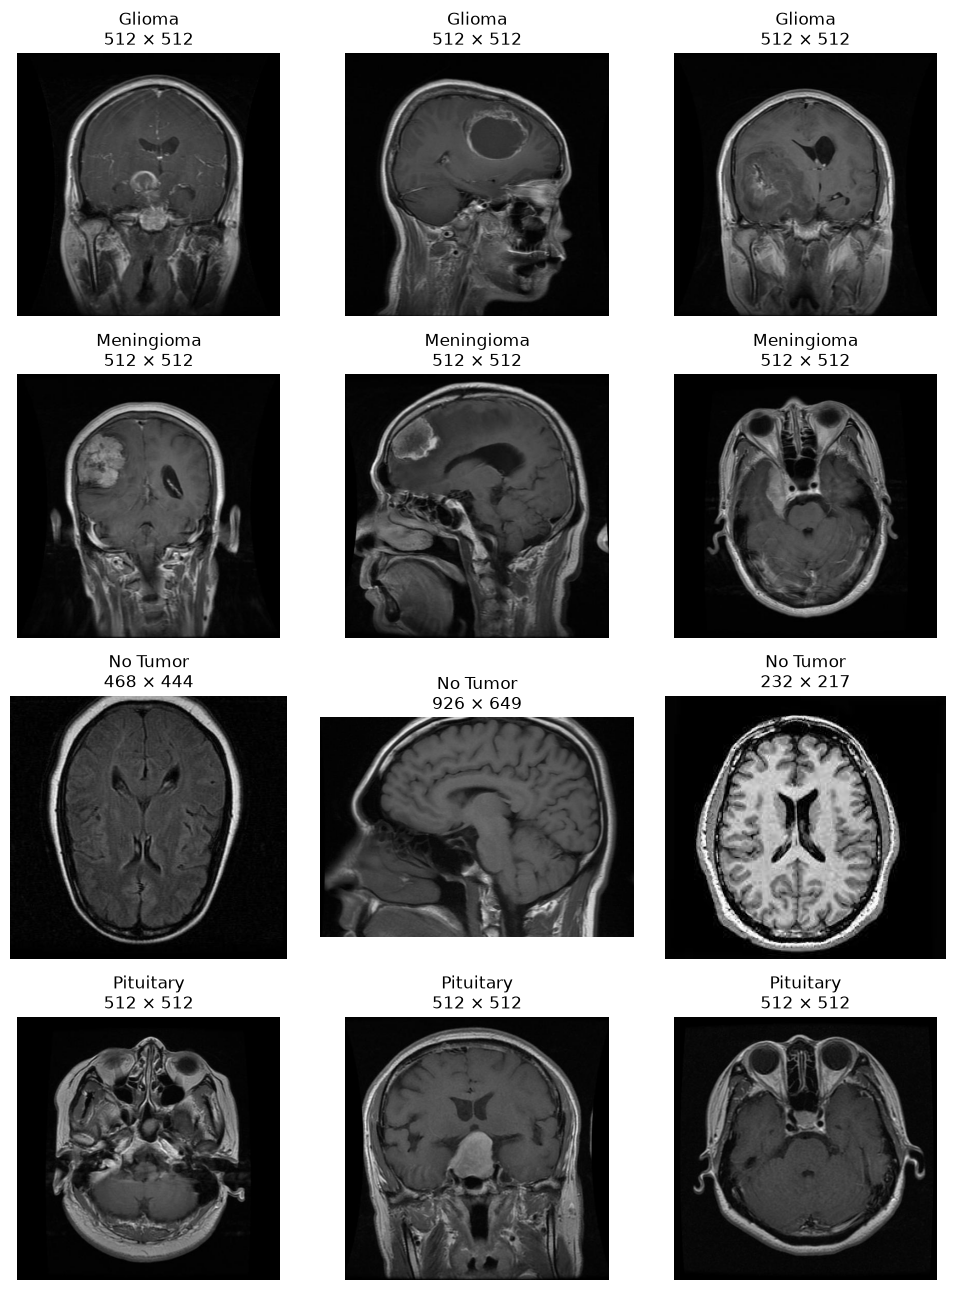

In [9]:
fig, axes = plt.subplots(4, 3, figsize=(10, 13))

classes = sorted(image_info["class"].unique())

for row, class_name in enumerate(classes):
    samples = (
        image_info[image_info["class"] == class_name]
        .sample(n=3, random_state=42)
    )

    for col, (_, sample) in enumerate(samples.iterrows()):
        image_path = (
            DATASET_DIR
            / sample["split"]
            / sample["class"]
            / "images"
            / sample["filename"]
        )

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(
            f"{class_name}\n{sample['width']} × {sample['height']}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## 8. Analyze Class Balance

Calculate the number and percentage of images per class in each split to identify class imbalance and compare the distributions of Train and Val.

In [10]:
class_distribution = class_counts.copy()

class_distribution["percentage"] = (
    class_distribution["image_count"]
    / class_distribution.groupby("split")["image_count"].transform("sum")
    * 100
)

class_distribution["percentage"] = class_distribution["percentage"].round(2)

class_distribution.sort_values(["split", "class"])

,split,class,image_count,percentage
0,Train,Glioma,1153,24.34
1,Train,Meningioma,1449,30.59
2,Train,No Tumor,711,15.01
3,Train,Pituitary,1424,30.06
4,Val,Glioma,136,26.56
5,Val,Meningioma,140,27.34
6,Val,No Tumor,100,19.53
7,Val,Pituitary,136,26.56


## 9. Check Duplicate Images

Use SHA-256 hashes to identify exact duplicate image files and check whether duplicate images occur across Train and Val, which could lead to data leakage during evaluation.

In [11]:
import hashlib

hash_records = []

for _, row in image_info.iterrows():
    image_path = (
        DATASET_DIR
        / row["split"]
        / row["class"]
        / "images"
        / row["filename"]
    )

    image_hash = hashlib.sha256(image_path.read_bytes()).hexdigest()

    hash_records.append({
        "split": row["split"],
        "class": row["class"],
        "filename": row["filename"],
        "sha256": image_hash,
    })

image_hashes = pd.DataFrame(hash_records)

duplicate_images = image_hashes[
    image_hashes.duplicated(subset="sha256", keep=False)
].sort_values("sha256")

duplicate_group_count = duplicate_images["sha256"].nunique()

cross_split_hashes = (
    image_hashes.groupby("sha256")["split"]
    .nunique()
)

cross_split_duplicate_groups = cross_split_hashes[
    cross_split_hashes > 1
]

print("Total images checked:", len(image_hashes))
print("Duplicate image groups:", duplicate_group_count)
print("Files involved in duplicates:", len(duplicate_images))
print(
    "Duplicate groups across Train and Val:",
    len(cross_split_duplicate_groups)
)

duplicate_images.head(10)

Total images checked: 5249
Duplicate image groups: 1228
Files involved in duplicates: 2564
Duplicate groups across Train and Val: 213


,split,class,filename,sha256
3335,Train,Pituitary,Te-pi_0049.jpg,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...
4649,Train,Pituitary,p (757).jpg,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...
1321,Train,Meningioma,Tr-me_0383.jpg,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...
2231,Train,Meningioma,m2 (112).jpg,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...
3465,Train,Pituitary,Tr-pi_0198.jpg,009bb0f6f6174828718de2b4566718aabaf61e819e5676...
4121,Train,Pituitary,p (278).jpg,009bb0f6f6174828718de2b4566718aabaf61e819e5676...
4090,Train,Pituitary,p (25).jpg,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...
5135,Val,Pituitary,Tr-pi_0167.jpg,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...
3431,Train,Pituitary,Tr-pi_0147.jpg,010841515b9457161c3065e47b2b983ebf5883edb809e2...
4070,Train,Pituitary,p (231).jpg,010841515b9457161c3065e47b2b983ebf5883edb809e2...


### 9.1. Summarize Duplicate Images

Count duplicate groups, identify duplicates shared across Train and Val, and check whether identical images have conflicting class labels.

In [12]:
duplicate_groups = (
    image_hashes.groupby("sha256")
    .agg(
        file_count=("filename", "size"),
        splits=("split", lambda x: sorted(set(x))),
        classes=("class", lambda x: sorted(set(x))),
        files=("filename", list),
    )
    .reset_index()
)

duplicate_groups = duplicate_groups[
    duplicate_groups["file_count"] > 1
].copy()

cross_split_duplicates = duplicate_groups[
    duplicate_groups["splits"].apply(
        lambda splits: len(splits) > 1
    )
]

label_conflicts = duplicate_groups[
    duplicate_groups["classes"].apply(
        lambda classes: len(classes) > 1
    )
]

print("Duplicate groups:", len(duplicate_groups))
print(
    "Files involved in duplicate groups:",
    duplicate_groups["file_count"].sum()
)
print("Duplicate groups across splits:", len(cross_split_duplicates))
print("Duplicate groups with conflicting labels:", len(label_conflicts))

print("\nDuplicates across splits:")
display(cross_split_duplicates.head(10))

print("\nDuplicates with conflicting labels:")
display(label_conflicts.head(10))

Duplicate groups: 1228
Files involved in duplicate groups: 2564
Duplicate groups across splits: 213
Duplicate groups with conflicting labels: 0

Duplicates across splits:


,sha256,file_count,splits,classes,files
12,00c30197dc30f7dd8b029ebd3a700d0d63833a434fa54a...,2,"[Train, Val]",[Pituitary],"[p (25).jpg, Tr-pi_0167.jpg]"
16,010bc80bb8c8dac8251662c1dd9c23d3a210aff06ed540...,2,"[Train, Val]",[Meningioma],"[Tr-me_0400.jpg, m2 (128).jpg]"
51,034fa02cddc4161d999241e4617fd1d1223249b8aeb76f...,2,"[Train, Val]",[Pituitary],"[p (225).jpg, Tr-pi_0140.jpg]"
60,039d0eb6b8493db695929536aa7476f8c472381a7c20de...,2,"[Train, Val]",[No Tumor],"[Tr-no_0253.jpg, image(266).jpg]"
106,06f85fe1e21a7aeb01b970b8561bc3059fa77daa01cb35...,2,"[Train, Val]",[Pituitary],"[p (31).jpg, Tr-pi_0234.jpg]"
143,098a2c1bd3db7c38f1e03283a9fc8948dc31a497f163dc...,2,"[Train, Val]",[No Tumor],"[image(317).jpg, Tr-no_0310.jpg]"
146,09b6d670376015de38a4bf375022757440c8888b1ffd75...,2,"[Train, Val]",[Pituitary],"[p (633).jpg, Te-pi_0018.jpg]"
148,09b9031e30e757eb6e648686f0ca412357e86895ebbc52...,3,"[Train, Val]",[Meningioma],"[Tr-me_0238.jpg, m1(16).jpg, m1(15).jpg]"
163,0ab28e8d7266b04f99dcd7c8c2f210e1fddec11f21d2e5...,2,"[Train, Val]",[Pituitary],"[p (575).jpg, Tr-pi_0524.jpg]"
164,0abe2a79782500fc6ec3c7082e46f7dd7da4725e87d71a...,2,"[Train, Val]",[Pituitary],"[p (10).jpg, Tr-piTr_0001.jpg]"



Duplicates with conflicting labels:


,sha256,file_count,splits,classes,files


In [13]:
print("Total duplicate groups:", len(duplicate_groups))
print(
    "Files involved in duplicates:",
    duplicate_groups["file_count"].sum()
)
print("Groups shared across splits:", len(cross_split_duplicates))
print(
    "Files involved in cross-split duplicates:",
    cross_split_duplicates["file_count"].sum()
)
print("Groups with conflicting labels:", len(label_conflicts))

Total duplicate groups: 1228
Files involved in duplicates: 2564
Groups shared across splits: 213
Files involved in cross-split duplicates: 474
Groups with conflicting labels: 0


## 10. Analyze Cross-Split Duplicates

Summarize the exact duplicate files shared across Train and Val by class and split to understand their distribution before cleaning the dataset.

In [14]:
cross_split_hash_set = set(cross_split_duplicates["sha256"])

cross_split_files = image_hashes[
    image_hashes["sha256"].isin(cross_split_hash_set)
].copy()

print("Cross-split duplicate files by split and class:")

display(
    cross_split_files
    .groupby(["split", "class"])
    .size()
    .unstack(fill_value=0)
)

print("\nCross-split duplicate groups by class:")

display(
    cross_split_duplicates
    .explode("classes")
    .groupby("classes")
    .agg(
        duplicate_groups=("sha256", "nunique"),
        files_involved=("file_count", "sum"),
    )
    .sort_values("duplicate_groups", ascending=False)
)

Cross-split duplicate files by split and class:


class,Glioma,Meningioma,No Tumor,Pituitary
split,,,,
Train,10,81,82,83
Val,9,78,54,77



Cross-split duplicate groups by class:


,duplicate_groups,files_involved
classes,,
Meningioma,77,159
Pituitary,77,160
No Tumor,50,136
Glioma,9,19


## 11. Analyze Within-Split Duplicates

Identify exact duplicate image groups occurring entirely within Train or entirely within Val, separately from duplicates shared across splits.

In [15]:
within_split_duplicates = duplicate_groups[
    duplicate_groups["splits"].apply(len) == 1
].copy()

within_split_duplicates["split"] = within_split_duplicates["splits"].str[0]

print("Duplicate groups within a single split:")
display(
    within_split_duplicates.groupby("split").agg(
        duplicate_groups=("sha256", "nunique"),
        files_involved=("file_count", "sum"),
    )
)

print("\nDuplicate groups by split and class:")
display(
    within_split_duplicates.explode("classes")
    .groupby(["split", "classes"])
    .agg(
        duplicate_groups=("sha256", "nunique"),
        files_involved=("file_count", "sum"),
    )
)

Duplicate groups within a single split:


,duplicate_groups,files_involved
split,,
Train,1007,2074
Val,8,16



Duplicate groups by split and class:


duplicate_groups  files_involved
split classes                                     
Train Glioma                    89             178
      Meningioma               402             809
      No Tumor                  78             199
      Pituitary                438             888
Val   Meningioma                 5              10
      No Tumor                   3               6


## 12. Estimate Unique Images per Split

Count unique image contents within each split and identify how many redundant file copies exist. This provides a baseline for planning dataset deduplication.

In [16]:
unique_counts = (
    image_hashes.groupby("split")
    .agg(
        total_files=("sha256", "size"),
        unique_images=("sha256", "nunique"),
    )
    .reset_index()
)

unique_counts["duplicate_copies"] = (
    unique_counts["total_files"] - unique_counts["unique_images"]
)

display(unique_counts)

print("\nOverall:")
print("Total files:", len(image_hashes))
print("Unique image contents:", image_hashes["sha256"].nunique())
print(
    "Redundant copies:",
    len(image_hashes) - image_hashes["sha256"].nunique()
)

,split,total_files,unique_images,duplicate_copies
0,Train,4737,3627,1110
1,Val,512,499,13



Overall:
Total files: 5249
Unique image contents: 3913
Redundant copies: 1336


## 13. Analyze Unique Images by Class

Count unique image contents by class and split to evaluate the impact of duplicates on class balance before preparing the cleaned dataset.

In [17]:
unique_per_split_class = (
    image_hashes
    .drop_duplicates(subset=["sha256", "split"])
    .groupby(["split", "class"])
    .size()
    .unstack(fill_value=0)
)

unique_overall_class = (
    image_hashes
    .drop_duplicates(subset="sha256")
    .groupby("class")
    .size()
)

print("Unique images per class and split:")
display(unique_per_split_class)

print("\nUnique images per class across the entire dataset:")
display(unique_overall_class.to_frame(name="unique_images"))

Unique images per class and split:


class,Glioma,Meningioma,No Tumor,Pituitary
split,,,,
Train,1063,1038,558,968
Val,136,134,93,136



Unique images per class across the entire dataset:


,unique_images
class,
Glioma,1190
Meningioma,1095
No Tumor,601
Pituitary,1027


## 14. Analyze Image Dimensions and Color Modes

Analyze image dimensions and color modes to identify inconsistencies and determine the preprocessing required before model training.

Top 15 image dimensions:


width  height
512    512       4206
225    225        119
630    630         66
442    442         42
236    236         33
256    256         25
201    251         23
       250         22
214    236         18
468    444         15
359    449         13
504    540         13
550    664         12
393    400         12
400    442         11
dtype: int64


Color modes:


mode
RGB     4247
L        998
RGBA       3
P          1
Name: count, dtype: int64

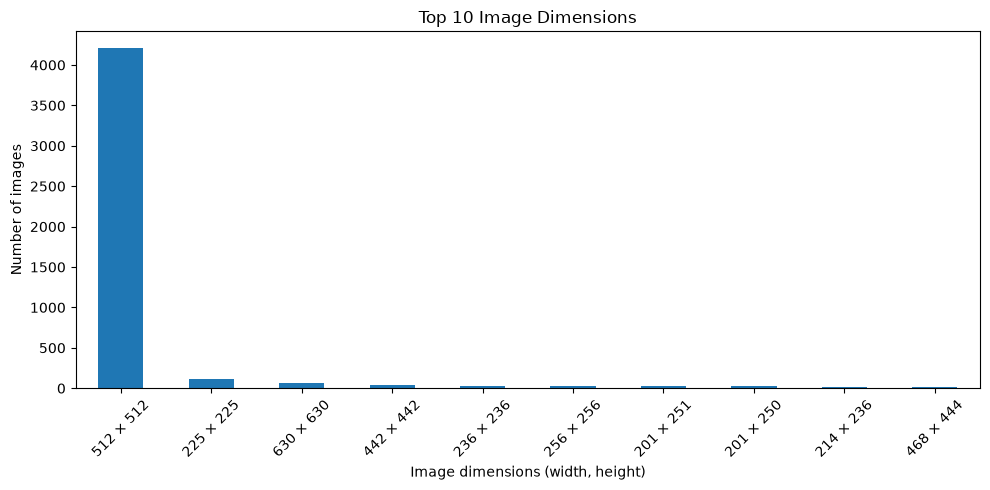

In [18]:

# 1. Most common image dimensions
print("Top 15 image dimensions:")
display(
    image_info.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

# 2. Image color modes
print("\nColor modes:")
display(image_info["mode"].value_counts())

# 3. Visualize the 10 most common dimensions
dimension_counts = (
    image_info.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
dimension_counts.plot(kind="bar")
plt.title("Top 10 Image Dimensions")
plt.xlabel("Image dimensions (width, height)")
plt.ylabel("Number of images")
plt.xticks(
    ticks=range(len(dimension_counts)),
    labels=[f"{w} × {h}" for w, h in dimension_counts.index],
    rotation=45
)
plt.tight_layout()
plt.show()


### Findings

- Most images are 512 × 512, but image dimensions are not uniform.
- RGB is the dominant color mode, while 998 images are grayscale.
- A small number of images use RGBA or palette-based modes.
- **Preprocessing decision:** Convert images to RGB and resize them to 299 × 299 for InceptionV3 during data loading.

## 15. Review Dataset Splits

Review the current dataset organization before preparing the required 70% training, 15% validation and 15% test sets.

In [20]:

for split_dir in sorted(DATASET_DIR.iterdir()):
    if not split_dir.is_dir():
        continue

    print(f"\n{split_dir.name}")

    for class_dir in sorted(split_dir.iterdir()):
        images_dir = class_dir / "images"

        if images_dir.is_dir():
            image_count = sum(
                1 for file in images_dir.iterdir()
                if file.is_file()
                and file.suffix.lower() in IMAGE_EXTENSIONS
            )
            print(f"  {class_dir.name}: {image_count} images")



Train
  Glioma: 1153 images
  Meningioma: 1449 images
  No Tumor: 711 images
  Pituitary: 1424 images

Val
  Glioma: 136 images
  Meningioma: 140 images
  No Tumor: 100 images
  Pituitary: 136 images



## 16. Inspect the Image Manifest

Review the existing `image_hashes` DataFrame created during duplicate analysis.

Check the available columns, total records, unique image contents, classes and original dataset splits.

We will reuse this DataFrame instead of recalculating image hashes.


In [21]:

print("Columns:", image_hashes.columns.tolist())

print("\nTotal image records:", len(image_hashes))
print("Unique image contents:", image_hashes["sha256"].nunique())

print("\nClasses:")
print(sorted(image_hashes["class"].unique()))

print("\nOriginal splits:")
print(sorted(image_hashes["split"].unique()))


Columns: ['split', 'class', 'filename', 'sha256']

Total image records: 5249
Unique image contents: 3913

Classes:
['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

Original splits:
['Train', 'Val']



## 17. Add and Verify Image Paths

Add the full path of each image to the existing manifest using its original split, class and filename.

Verify that the paths exist before using the manifest to prepare the classification dataset. This step does not move, copy or delete any files.


In [22]:

# Create a copy so the original manifest stays unchanged
image_manifest = image_hashes.copy()

# Reconstruct each image's full path
image_manifest["path"] = image_manifest.apply(
    lambda row: DATASET_DIR
    / row["split"]
    / row["class"]
    / "images"
    / row["filename"],
    axis=1
)

# Check whether each path exists
image_manifest["path_exists"] = image_manifest["path"].map(
    lambda path: path.is_file()
)

print("Total records:", len(image_manifest))
print("Existing image files:", image_manifest["path_exists"].sum())
print("Missing image files:", (~image_manifest["path_exists"]).sum())

print("\nExample paths:")
display(image_manifest[["split", "class", "filename", "path"]].head())


Total records: 5249
Existing image files: 5249
Missing image files: 0

Example paths:


,split,class,filename,path
0,Train,Glioma,Te-glTr_0000.jpg,/home/lahcen404/YouCode-Y2/BrainScanAI-V2/data...
1,Train,Glioma,Te-glTr_0005.jpg,/home/lahcen404/YouCode-Y2/BrainScanAI-V2/data...
2,Train,Glioma,Te-glTr_0007.jpg,/home/lahcen404/YouCode-Y2/BrainScanAI-V2/data...
3,Train,Glioma,Te-gl_0014.jpg,/home/lahcen404/YouCode-Y2/BrainScanAI-V2/data...
4,Train,Glioma,Te-gl_0015.jpg,/home/lahcen404/YouCode-Y2/BrainScanAI-V2/data...



## 18. Check Duplicate Images Across Classes

Check whether identical image contents, identified by their SHA-256 hashes, have been assigned to different classes.

Images with conflicting labels must be investigated before preparing the final dataset splits.


In [23]:

class_counts_per_hash = image_manifest.groupby("sha256")["class"].nunique()

conflicting_hashes = class_counts_per_hash[
    class_counts_per_hash > 1
]

print("Unique image hashes:", image_manifest["sha256"].nunique())
print("Hashes assigned to multiple classes:", len(conflicting_hashes))

if len(conflicting_hashes) > 0:
    conflicting_images = image_manifest[
        image_manifest["sha256"].isin(conflicting_hashes.index)
    ].sort_values("sha256")

    display(conflicting_images[["sha256", "class", "split", "filename"]])
else:
    print("No conflicting class labels found.")


Unique image hashes: 3913
Hashes assigned to multiple classes: 0
No conflicting class labels found.



## 19. Create the Unique Image Manifest

Create a DataFrame containing one record per unique image using its SHA-256 hash.

Keep the class label and image path so the images can be organized into Train, Validation and Test sets later. The original dataset remains unchanged.


In [24]:

unique_manifest = (
    image_manifest
    .sort_values(["sha256", "split", "filename"])
    .drop_duplicates(subset="sha256", keep="first")
    .reset_index(drop=True)
)

print("Original image records:", len(image_manifest))
print("Unique image records:", len(unique_manifest))
print("Duplicate copies excluded:", len(image_manifest) - len(unique_manifest))

print("\nUnique images per class:")
display(
    unique_manifest["class"]
    .value_counts()
    .sort_index()
    .to_frame(name="unique_images")
)


Original image records: 5249
Unique image records: 3913
Duplicate copies excluded: 1336

Unique images per class:


,unique_images
class,
Glioma,1190
Meningioma,1095
No Tumor,601
Pituitary,1027



## 20. Split the Dataset into Train, Validation and Test

Split the unique image records into 70% training, 15% validation and 15% test sets.

Use stratified splitting to preserve the class proportions in each set. The test set will remain separate for final model evaluation.


In [25]:
from sklearn.model_selection import train_test_split

train_df,temp_df = train_test_split(
    unique_manifest,
    test_size=0.30,
    random_state=42,
    stratify=unique_manifest["class"]
)

val_df,test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["class"]
)

total = len(unique_manifest)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(df)} images ({len(df) / total:.1%})")

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))


Train: 2739 images (70.0%)
Validation: 587 images (15.0%)
Test: 587 images (15.0%)

Total: 3913



## 21. Analyze Class Distribution Across Splits

Count the images belonging to each class in Train, Validation and Test.

Calculate the percentage of each class within every split to verify that stratification has preserved a similar class distribution.


In [26]:

splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

class_counts = pd.DataFrame({
    name: df["class"].value_counts()
    for name, df in splits.items()
}).fillna(0).astype(int)

class_percentages = (
    class_counts.div(class_counts.sum(axis=0), axis=1) * 100
).round(2)

print("Image counts per class:")
display(class_counts)

print("\nClass percentages within each split:")
display(class_percentages)


Image counts per class:


,Train,Validation,Test
class,,,
Glioma,833,178,179
Meningioma,766,165,164
Pituitary,719,154,154
No Tumor,421,90,90



Class percentages within each split:


,Train,Validation,Test
class,,,
Glioma,30.41,30.32,30.49
Meningioma,27.97,28.11,27.94
Pituitary,26.25,26.24,26.24
No Tumor,15.37,15.33,15.33



## 22. Verify Duplicate Separation Across Splits

Check that no identical image content appears in more than one of the Train, Validation and Test sets.

Compare the SHA-256 hashes between splits to verify that the dataset separation prevents exact-duplicate leakage.


In [27]:

train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
test_hashes = set(test_df["sha256"])

train_val_overlap = train_hashes & val_hashes
train_test_overlap = train_hashes & test_hashes
val_test_overlap = val_hashes & test_hashes

print("Train–Validation duplicate hashes:", len(train_val_overlap))
print("Train–Test duplicate hashes:", len(train_test_overlap))
print("Validation–Test duplicate hashes:", len(val_test_overlap))

if not train_val_overlap and not train_test_overlap and not val_test_overlap:
    print("\nSuccess: no identical image hashes are shared between splits.")
else:
    print("\nWarning: duplicate leakage detected.")


Train–Validation duplicate hashes: 0
Train–Test duplicate hashes: 0
Validation–Test duplicate hashes: 0

Success: no identical image hashes are shared between splits.



## 23. Create the Final Split Manifest

Combine the Train, Validation and Test DataFrames into one manifest.

Add a `dataset_split` column to record each image's new assignment while preserving its original split, class, filename, SHA-256 hash and path.

Save the manifest as a CSV file so the split can be reproduced without modifying the original dataset.


In [28]:

# Label each DataFrame with its new split
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["dataset_split"] = "Train"
val_df["dataset_split"] = "Validation"
test_df["dataset_split"] = "Test"

# Combine all three splits
final_manifest = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Keep the important columns in a clear order
final_manifest = final_manifest[
    ["dataset_split", "split", "class", "filename", "sha256", "path"]
]

# Save the manifest
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = REPORTS_DIR / "classification_split_manifest.csv"
final_manifest.to_csv(manifest_path, index=False)

print("Total records:", len(final_manifest))
print("\nImages per new split:")
print(final_manifest["dataset_split"].value_counts())

print("\nSaved manifest to:")
print(manifest_path)


Total records: 3913

Images per new split:
dataset_split
Train         2739
Validation     587
Test           587
Name: count, dtype: int64

Saved manifest to:
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/reports/classification_split_manifest.csv



## 24. Create the Clean Classification Dataset

Create a separate directory containing the unique images assigned to Train, Validation and Test.

Organize the images into class-specific folders so Keras can infer their labels when loading the dataset. Copy the images without modifying the original dataset.


In [29]:

import shutil

CLEAN_DATASET_DIR = PROJECT_ROOT / "data" / "classification_clean"

# Create the required split and class folders
for split_name in ["Train", "Validation", "Test"]:
    for class_name in sorted(final_manifest["class"].unique()):
        (CLEAN_DATASET_DIR / split_name / class_name).mkdir(
            parents=True,
            exist_ok=True
        )

# Copy each unique image into its assigned folder
copied_count = 0

for row in final_manifest.itertuples(index=False):
    source_path = Path(row.path)
    destination_path = (
        CLEAN_DATASET_DIR
        / row.dataset_split
        / row._2
        / row.filename
    )

    shutil.copy2(source_path, destination_path)
    copied_count += 1

print("Images copied:", copied_count)
print("Dataset location:", CLEAN_DATASET_DIR)


Images copied: 3913
Dataset location: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/data/classification_clean


In [30]:

copied_count = 0

for _, row in final_manifest.iterrows():
    source_path = Path(row["path"])
    destination_path = (
        CLEAN_DATASET_DIR
        / row["dataset_split"]
        / row["class"]
        / row["filename"]
    )

    shutil.copy2(source_path, destination_path)
    copied_count += 1

print("Images copied:", copied_count)
print("Dataset location:", CLEAN_DATASET_DIR)


Images copied: 3913
Dataset location: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/data/classification_clean



## 25. Verify the Clean Classification Dataset

Check that the clean dataset contains the expected classes and image counts for Train, Validation and Test.

Compare the actual folder contents with the saved split manifest to ensure that all images were copied correctly.


In [31]:

expected_counts = (
    final_manifest
    .groupby(["dataset_split", "class"])
    .size()
    .unstack(fill_value=0)
)

actual_counts = {}

for split_name in ["Train", "Validation", "Test"]:
    actual_counts[split_name] = {}

    for class_name in sorted(final_manifest["class"].unique()):
        class_dir = CLEAN_DATASET_DIR / split_name / class_name

        image_files = [
            path for path in class_dir.iterdir()
            if path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        ]

        actual_counts[split_name][class_name] = len(image_files)

actual_counts_df = pd.DataFrame(actual_counts).T
actual_counts_df.index.name = "dataset_split"

print("Expected image counts:")
display(expected_counts)

print("\nActual image counts:")
display(actual_counts_df)

print("\nCounts match:", (
    expected_counts.reindex(actual_counts_df.index).equals(actual_counts_df)
))


Expected image counts:


class,Glioma,Meningioma,No Tumor,Pituitary
dataset_split,,,,
Test,179,164,90,154
Train,833,766,421,719
Validation,178,165,90,154



Actual image counts:


,Glioma,Meningioma,No Tumor,Pituitary
dataset_split,,,,
Train,833,766,421,719
Validation,178,165,90,154
Test,179,164,90,154



Counts match: True
